<a href="https://colab.research.google.com/github/nasif-raihan/GSU/blob/main/CSCI_7090_Module_6_Lab_CNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Module 6 — Convolutional Neural Networks (Lab)
**Computer Vision · Deep Learning**

**Part A** walks one image through the CNN pipeline (convolution → ReLU → pooling → flatten → dense) so you can *see* what each layer does. **Part B** builds and trains a small CNN on the digits dataset and visualizes its learned feature maps. Runs anywhere — a built-in image and dataset, no Drive.

## Part A — What each layer does
### A1. Load an image (built-in) and add a batch dimension
A CNN expects a 4-D tensor: (batch, height, width, channels).

Input shape: (1, 128, 128, 1)


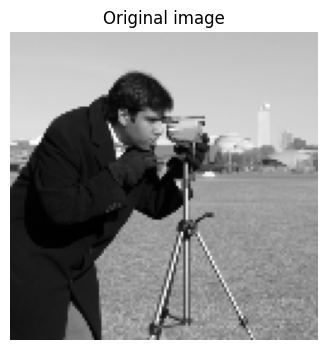

In [1]:
import numpy as np, tensorflow as tf
import matplotlib.pyplot as plt
from skimage import data
plt.rc("image", cmap="gray")

img = data.camera().astype(np.float32) / 255.0            # 512x512 grayscale, in [0,1]
img = tf.image.resize(img[..., np.newaxis], [128, 128])   # (128,128,1)
image = tf.expand_dims(img, axis=0)                        # (1,128,128,1)
print("Input shape:", image.shape)
plt.figure(figsize=(4,4)); plt.imshow(tf.squeeze(image)); plt.title("Original image"); plt.axis("off"); plt.show()

### A2. Convolution
A 3×3 edge-detection kernel (a Laplacian) slides over the image. Kernel shape is (kh, kw, in_channels, out_channels).

---
The Master Identification Checklist:

- Does the matrix sum to 0 and Split down the middle (left/right or top/bottom)??
>  $\rightarrow$ **Sobel** Kernel (directional first derivative).

- Does the matrix sum to 0 and Rotational symmetry with center opposite to outer cells?
>  $\rightarrow$ **Laplacian** Kernel (second derivative).

- Does the matrix sum to 1 with a high central value and negative outer values?
> $\rightarrow$ **Sharpen** Kernel.

- Are all values positive & matrix sum to 1?
> $\rightarrow$ It's a Smoothing/Blur kernel (**Gaussian** if center is weighted higher, **Box** Blur if all numbers are equal).


After convolution: (1, 128, 128, 1)


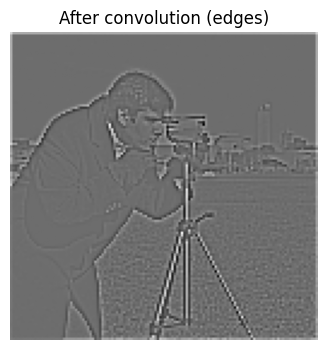

In [2]:
kernel = tf.constant([[-1,-1,-1],[-1,8,-1],[-1,-1,-1]], dtype=tf.float32)
kernel = tf.reshape(kernel, [3, 3, 1, 1])
conv = tf.nn.conv2d(image, kernel, strides=1, padding="SAME")
print("After convolution:", conv.shape)
plt.figure(figsize=(4,4)); plt.imshow(tf.squeeze(conv)); plt.title("After convolution (edges)"); plt.axis("off"); plt.show()

### A3. ReLU activation
ReLU zeros out negative responses, introducing non-linearity.

After ReLU: (1, 128, 128, 1)


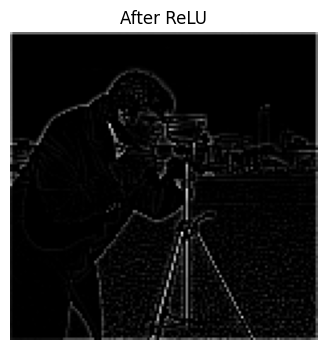

In [3]:
relu = tf.nn.relu(conv)
print("After ReLU:", relu.shape)
plt.figure(figsize=(4,4)); plt.imshow(tf.squeeze(relu)); plt.title("After ReLU"); plt.axis("off"); plt.show()

### A4. Max pooling
2×2 max pooling with stride 2 halves the height and width, keeping the strongest responses.

After pooling: (1, 64, 64, 1)


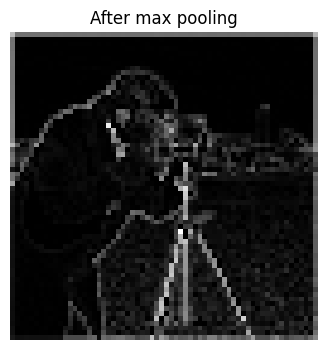

In [4]:
pool = tf.nn.max_pool2d(relu, ksize=2, strides=2, padding="SAME")
print("After pooling:", pool.shape)   # 128 -> 64
plt.figure(figsize=(4,4)); plt.imshow(tf.squeeze(pool)); plt.title("After max pooling"); plt.axis("off"); plt.show()

### A5. Flatten → Dense
Flatten turns the feature map into a vector; a dense layer then does the high-level reasoning.

In [5]:
flat = tf.keras.layers.Flatten()(pool)
print("After flatten:", flat.shape)             # 64*64 = 4096
dense = tf.keras.layers.Dense(64, activation="relu")(flat)
print("After dense(64):", dense.shape)

After flatten: (1, 4096)
After dense(64): (1, 64)


## Part B — Build & train a small CNN
### B1. Data (digits as 8×8 images)

In [6]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

digits = load_digits()
X = digits.images[..., np.newaxis] / 16.0        # (n, 8, 8, 1), scaled to [0,1]
y = digits.target
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print("train:", Xtr.shape, "| test:", Xte.shape)

train: (1437, 8, 8, 1) | test: (360, 8, 8, 1)


### B2. Define the CNN
Conv → ReLU → Pool → Conv → ReLU → Flatten → Dense → Softmax — the small pattern from the doc.

In [7]:
model = tf.keras.Sequential([
    tf.keras.layers.Input((8, 8, 1)),
    tf.keras.layers.Conv2D(16, 3, padding="same", activation="relu"),
    tf.keras.layers.MaxPooling2D(2),
    tf.keras.layers.Conv2D(32, 3, padding="same", activation="relu"),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dense(10, activation="softmax"),
])
model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 8, 8, 16)       │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 4, 4, 16)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 4, 4, 32)       │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │        32,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 38,282 (149.54 KB)

 Trainable params: 38,282 (149.54 KB)

 Non-trainable params: 0 (0.00 B)

### B3. Train and evaluate

Test accuracy: 0.9722


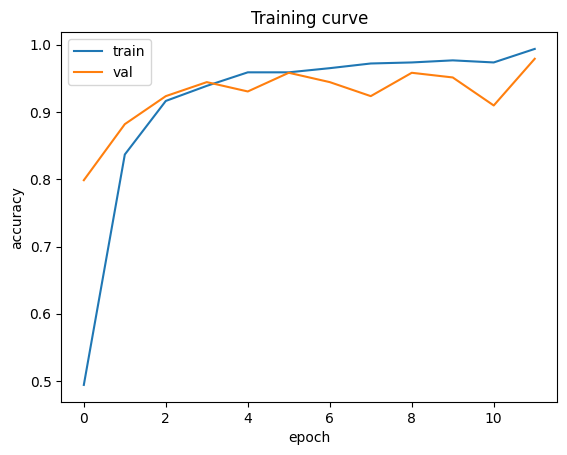

In [8]:
hist = model.fit(Xtr, ytr, validation_split=0.1, epochs=12, batch_size=32, verbose=0)
test_acc = model.evaluate(Xte, yte, verbose=0)[1]
print(f"Test accuracy: {test_acc:.4f}")
plt.plot(hist.history["accuracy"], label="train")
plt.plot(hist.history["val_accuracy"], label="val")
plt.xlabel("epoch"); plt.ylabel("accuracy"); plt.legend(); plt.title("Training curve"); plt.show()

### B4. Visualize learned feature maps
The first conv layer's 16 filters each produce a feature map — the network's learned edge/texture detectors.

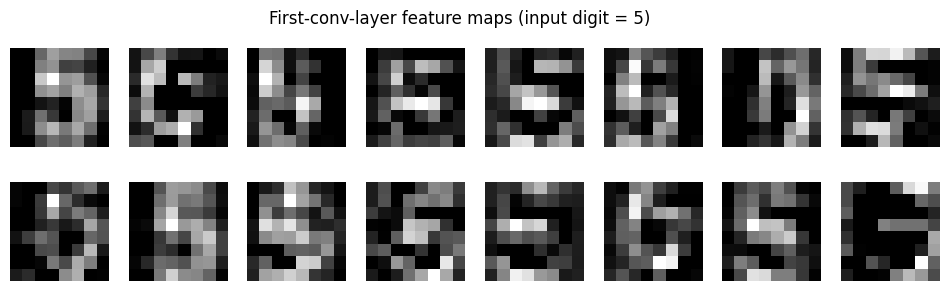

In [9]:
feat_model = tf.keras.Sequential(model.layers[:1])     # just the first conv layer
fmaps = feat_model.predict(Xte[:1], verbose=0)         # (1, 8, 8, 16)
fig, axs = plt.subplots(2, 8, figsize=(12, 3.2))
for i, ax in enumerate(axs.ravel()):
    ax.imshow(fmaps[0, :, :, i]); ax.axis("off")
plt.suptitle(f"First-conv-layer feature maps (input digit = {yte[0]})"); plt.show()